<h1> Data Preperation

Load in Labelled Windows

In [36]:
from label_reading_tools import labelled_data_loading

width = 80
height = 120

root_folder = f"G:/CNN Formatted Data - {width} x {height}"

height += 1
width += 1

# windows not fitting the correct dimentions for a CNN are immediatly filtered in this loading process
# available labels = ["c", "p", "e", "n", "u", "f"]

win_raw, win_filtered, labels = labelled_data_loading(root_folder, width, height, ["c", "p", "e", "n", "f"])

import numpy as np
num_classes = len(np.unique(labels))
print(f'Total Classes: {num_classes}')

from collections import Counter
print(f'Class Counts: {Counter(labels)}')

Total Samples: 15343
Total Classes: 5
Class Counts: Counter({'f': 6227, 'p': 4843, 'c': 2859, 'e': 921, 'n': 493})


Spectrograms for the Windows

In [37]:
from copy import deepcopy

stacks = []
for win in win_raw:
    stack = None
    for i in range(len(win[0])):
        if stack is None:
            stack = deepcopy(win[:, i])
        else:
            stack = stack + win[:, i]

    stack = stack / len(win[0])
    stacks.append(stack)

In [38]:
from scipy import signal
import matplotlib.pyplot as plt

spectrograms = []
for stack in stacks:
    f, t, Sxx = signal.spectrogram(stack, 1000, nperseg=12, mode= "magnitude")
    spectrograms.append(Sxx)

    # fig = plt.figure()
    # ax = fig.add_subplot()
    # ax.set_ylim(0, 500)
    # cmap = plt.colormaps['viridis']
    # img1 = plt.pcolormesh(t, f, Sxx, cmap=cmap)
    #
    # plt.ylabel('Frequency [Hz]')
    # plt.xlabel('Time [sec]')
    # fig.colorbar(img1, label= "Nano Strain per Second [nm/m/s]")
    # break

Normalising Windows

In [39]:
# this normalises windows (between -1, 1) individually as normalising as a group leads to inconsistent normalization
import numpy as np

win_raw_normalised = []
win_filtered_normalised = []
spectrograms_normalised = []
for w, f, s in zip(win_raw, win_filtered, spectrograms):

    minVal = w.min()
    maxVal = w.max()

    w_normalised = (((w - minVal) / (maxVal - minVal)) - 0.5) * 2
    win_raw_normalised.append(w_normalised)

    minVal = f.min()
    maxVal = f.max()

    f_normalised = (((f - minVal) / (maxVal - minVal)) - 0.5) * 2
    win_filtered_normalised.append(f_normalised)

    minVal = s.min()
    maxVal = s.max()

    s_normalised = (((s - minVal) / (maxVal - minVal)) - 0.5) * 2
    spectrograms_normalised.append(s_normalised)

win_raw_normalised = np.array(win_raw_normalised)
win_filtered_normalised = np.array(win_filtered_normalised)
spectrograms_normalised = np.array(spectrograms_normalised)

Class Selection and One Hot Encoding

In [ ]:
# footsteps vs other
for l in labels:
    if l != "f":
        labels[labels == l] = "o"

In [ ]:
# potential cracking vs other
for l in labels:
    if l != "c":
        labels[labels == l] = "o"

In [40]:
from keras.src.utils import to_categorical
labels = np.array(labels)

unique = np.unique(labels)
print(unique)

for i, u in enumerate(unique):
    labels[labels == u] = i

labels_ohe = to_categorical(labels, num_classes=num_classes)

print(labels_ohe[0])

['c' 'e' 'f' 'n' 'p']
[1. 0. 0. 0. 0.]


Balancing Classes (Experiment with Binary vs Multiclass)

In [41]:
# general purpose balancing
win_raw_normalised_balanced = []
win_filtered_normalised_balanced = []
spectrograms_normalised_balanced = []
labels_ohe_balanced = []
labels_balanced = []

smallest_class = min(Counter(labels).values())

for i in range(num_classes):
    count = 0
    for w, wf, s, ohe, l in zip(win_raw_normalised, win_filtered_normalised, spectrograms_normalised, labels_ohe, labels):
        if count == smallest_class:
            break
        else:
            if l == f'{i}':
                labels_balanced.append(l)
                labels_ohe_balanced.append(ohe)
                spectrograms_normalised_balanced.append(s)
                win_raw_normalised_balanced.append(w)
                win_filtered_normalised_balanced.append(wf)
                count+=1

In [42]:
Counter(labels_balanced)

Counter({'0': 493, '1': 493, '2': 493, '3': 493, '4': 493})

Reshape Window For CNN

In [43]:
win_raw_normalised = np.array(win_raw_normalised).astype(np.float32)
win_raw_normalised = win_raw_normalised.reshape(-1, 1, height, width)

win_filtered_normalised = np.array(win_filtered_normalised).astype(np.float32)
win_filtered_normalised = win_filtered_normalised.reshape(-1, 1, height, width)

spectrograms_normalised = np.array(spectrograms_normalised).astype(np.float32)
spectrograms_normalised = spectrograms_normalised.reshape(-1, 1, height, width)

In [46]:
win_raw_normalised_balanced = np.array(win_raw_normalised_balanced).astype(np.float32)
win_raw_normalised_balanced = win_raw_normalised_balanced.reshape(-1, 1, height, width)

win_filtered_normalised_balanced = np.array(win_filtered_normalised_balanced).astype(np.float32)
win_filtered_normalised_balanced = win_filtered_normalised_balanced.reshape(-1, 1, height, width)

spectrograms_normalised_balanced = np.array(spectrograms_normalised_balanced).astype(np.float32)
spectrograms_normalised_balanced = spectrograms_normalised_balanced.reshape(-1, 1, 7, 10)

<h1> Machine Learning

In [47]:
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# random seed
random_seed = 2

# train validation split
win_raw_train, temp_win, labels_train_enc, temp_label = train_test_split(np.array(win_raw_normalised_balanced), np.array(labels_ohe_balanced),
                                                                         test_size=0.3)
win_raw_val, win_raw_test, labels_val_enc, labels_test_enc = train_test_split(temp_win, temp_label,
                                                                              test_size=0.5)

print(f"Train: {len(win_raw_train)}")
print(f"Validation: {len(win_raw_val)}")
print(f"Test: {len(win_raw_test)}")

train_dataset = TensorDataset(torch.from_numpy(win_raw_train), torch.from_numpy(labels_train_enc))
train_loader = DataLoader(train_dataset, shuffle=True, batch_size=16)

val_dataset = TensorDataset(torch.from_numpy(win_raw_val), torch.from_numpy(labels_val_enc))
val_loader = DataLoader(val_dataset, shuffle=True, batch_size=16)

test_dataset = TensorDataset(torch.from_numpy(win_raw_test), torch.from_numpy(labels_test_enc))
test_loader = DataLoader(test_dataset, shuffle=True, batch_size=16)

Train: 1725
Validation: 370
Test: 370


In [16]:
import torch.nn as nn
import torch.nn.functional as F

class MyFirstNeuralNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 12, 5) # (input (121) - kernal (5) / stride (1)) + 1 -> (12, 117, 77)
        self.pool = nn.MaxPool2d(2, 2) # (12, 58, 38) pooling always floors
        self.conv2 = nn.Conv2d(12, 24, 5) #(24, 54, 34) -> pool again (24, 27, 17)
        self.fc1 = nn.Linear(24 * 27 * 17, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 5) # input and final output are the only fixed values

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [27]:
class AdvancedNeuralNet(nn.Module):
    def __init__(self):
        super().__init__()

        # (input (121) - kernal (3) / stride (1)) + 1 -> (32, 119, 79)
        # (32, 59, 39) pooling always floors

        self.conv1 = nn.Conv2d(1, 32, 3) #119, 79
        self.conv2 = nn.Conv2d(32, 64, 3) #117, 77
        self.bthNorm = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2) #58, 38

        self.conv3 = nn.Conv2d(64, 128, 3) #56, 36
        self.conv4 = nn.Conv2d(128, 256, 3) #54, 34
        self.conv5 = nn.Conv2d(256, 512, 3) #52, 32
        self.bthNorm2 = nn.BatchNorm2d(512)

        self.fc1 = nn.Linear((512 * 26 * 16), 1024)
        self.drp = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(1024, 256)
        self.fc3 = nn.Linear(256, 64)
        self.fc4 = nn.Linear(64, 5)



    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.bthNorm(x)
        x = self.pool(x)

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))
        x = self.bthNorm2(x)
        x = self.pool(x)

        x = torch.flatten(x, 1)
        x = self.drp(F.relu(self.fc1(x)))
        x = self.drp(F.relu(self.fc2(x)))
        x = self.drp(F.relu(self.fc3(x)))
        x = F.softmax(self.fc4(x))
        return x

Network Training

In [48]:
from PyTorch_Darknet53_master.model import darknet53

import torch.nn as nn
import torch.optim as optim

model_save = './models/testing.pth'

num_epochs = 50
net = darknet53(num_classes)
# net = AdvancedNeuralNet()

if torch.cuda.is_available():
    net = net.cuda()

loss_function = nn.CrossEntropyLoss()

# optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
# optimizer = optim.Adam(net.parameters(), lr=0.001)
optimizer = optim.Adam(net.parameters(), lr=0.0001)

min_valid_loss = np.inf

for e in range(num_epochs):
    train_loss = 0.0
    net.train()  # Optional when not using Model Specific layer
    for data, train_labels in train_loader:
        if torch.cuda.is_available():
            data, train_labels = data.cuda(), train_labels.cuda()

        optimizer.zero_grad()

        target = net(data)
        loss = loss_function(target, train_labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    valid_loss = 0.0
    net.eval()  # Optional when not using Model Specific layer
    with torch.no_grad():
        for data, val_labels in val_loader:
            if torch.cuda.is_available():
                data, val_labels = data.cuda(), val_labels.cuda()

            target = net(data)
            loss = loss_function(target, val_labels)
            valid_loss = loss.item() * data.size(0)

    print(f'Epoch {e + 1} \t\t Training Loss: {train_loss / len(train_loader)} \t\t Validation Loss: {valid_loss / len(val_loader)}')

    if min_valid_loss > valid_loss:
        print(f'Validation Loss Decreased({min_valid_loss:.6f}--->{valid_loss:.6f}) \t Saving The Model')
        min_valid_loss = valid_loss
        # Saving State Dict
        torch.save(net.state_dict(), model_save)

Epoch 1 		 Training Loss: 1.1869902424431078 		 Validation Loss: 0.0409745080396533
Validation Loss Decreased(inf--->0.983388) 	 Saving The Model
Epoch 2 		 Training Loss: 0.9011599459756541 		 Validation Loss: 0.06046081924190124
Epoch 3 		 Training Loss: 0.8069068660816012 		 Validation Loss: 0.07802896946668625
Epoch 4 		 Training Loss: 0.7457018120454422 		 Validation Loss: 0.13905460635821024
Epoch 5 		 Training Loss: 0.6539200611927947 		 Validation Loss: 0.07699945072283754
Epoch 6 		 Training Loss: 0.6256033030121286 		 Validation Loss: 0.01030041060099999
Validation Loss Decreased(0.983388--->0.247210) 	 Saving The Model
Epoch 7 		 Training Loss: 0.5197969468487404 		 Validation Loss: 0.05551220973332723
Epoch 8 		 Training Loss: 0.3595947025304677 		 Validation Loss: 0.11782659714420636
Epoch 9 		 Training Loss: 0.3469378924827418 		 Validation Loss: 0.29333701233069104
Epoch 10 		 Training Loss: 0.2251522413655198 		 Validation Loss: 0.060312862818439804
Epoch 11 		 Training

Network Testing

In [49]:
import numpy as np
import torch

train_net = darknet53(num_classes)
# train_net = AdvancedNeuralNet()

train_net.load_state_dict(torch.load(model_save))

correct = 0
total = 0

# Confusion matrix: rows = actual, columns = predicted
confusion = np.zeros((num_classes, num_classes), dtype=int)

train_net.eval()

with torch.no_grad():
    for data in test_loader:
        images, test_labels = data

        outputs = train_net(images)
        _, predicted = torch.max(outputs.data, 1)

        total += test_labels.size(0)

        for l, p in zip(test_labels, predicted):
            actual = torch.argmax(l).item()  # convert one-hot label to class index
            pred = p.item()

            confusion[actual, pred] += 1

            if actual == pred:
                correct += 1

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

print("\nConfusion Matrix")
print("(rows=actual, cols=predicted)")
print(confusion)

# Per-class statistics
for c in range(num_classes):
    true_positive = confusion[c, c]
    false_positive = confusion[:, c].sum() - true_positive
    false_negative = confusion[c, :].sum() - true_positive

    print(
        f"Class {c}: "
        f"TP={true_positive}, "
        f"FP={false_positive}, "
        f"FN={false_negative}"
    )

Test Accuracy: 62.43%

Confusion Matrix
(rows=actual, cols=predicted)
[[58  0  0  1 14]
 [ 0 47 10 18  0]
 [ 0  6 53 17  2]
 [ 0 15 18 41  0]
 [29  0  6  3 32]]
Class 0: TP=58, FP=29, FN=15
Class 1: TP=47, FP=21, FN=28
Class 2: TP=53, FP=34, FN=25
Class 3: TP=41, FP=39, FN=33
Class 4: TP=32, FP=16, FN=38


Auto Encoder

In [50]:
from keras import layers, losses
from keras.models import Model, Sequential

class SimpleAutoencoder(Model):
    def __init__(self, latent_dimensions):
        super(SimpleAutoencoder, self).__init__()
        self.encoder = Sequential([
            layers.Input(shape=(1, 121, 81)), #this is going to need editing
            layers.Flatten(),
            layers.Dense(latent_dimensions, activation='relu'),
        ])

        self.decoder = Sequential([
            layers.Dense(121 * 81, activation='tanh'),
            layers.Reshape((1, 121, 81))
        ])

    def call(self, input_data):
        encoded = self.encoder(input_data)
        decoded = self.decoder(encoded)
        return decoded

In [51]:
x_train, x_test, y_train, y_test = train_test_split(np.array(win_raw_normalised_balanced), np.array(labels_ohe_balanced),
                                                    test_size=0.3)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0795 - val_loss: 0.0684
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0610 - val_loss: 0.0586
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0561 - val_loss: 0.0559
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0520 - val_loss: 0.0500
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0467 - val_loss: 0.0459
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0436 - val_loss: 0.0435
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0414 - val_loss: 0.0416
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0393 - val_loss: 0.0395
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0372 - val_loss: 0.0375
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0351 - val_loss: 0.0358
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0335 - val_loss: 0.0345
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0322 - val_loss: 0.0338
E

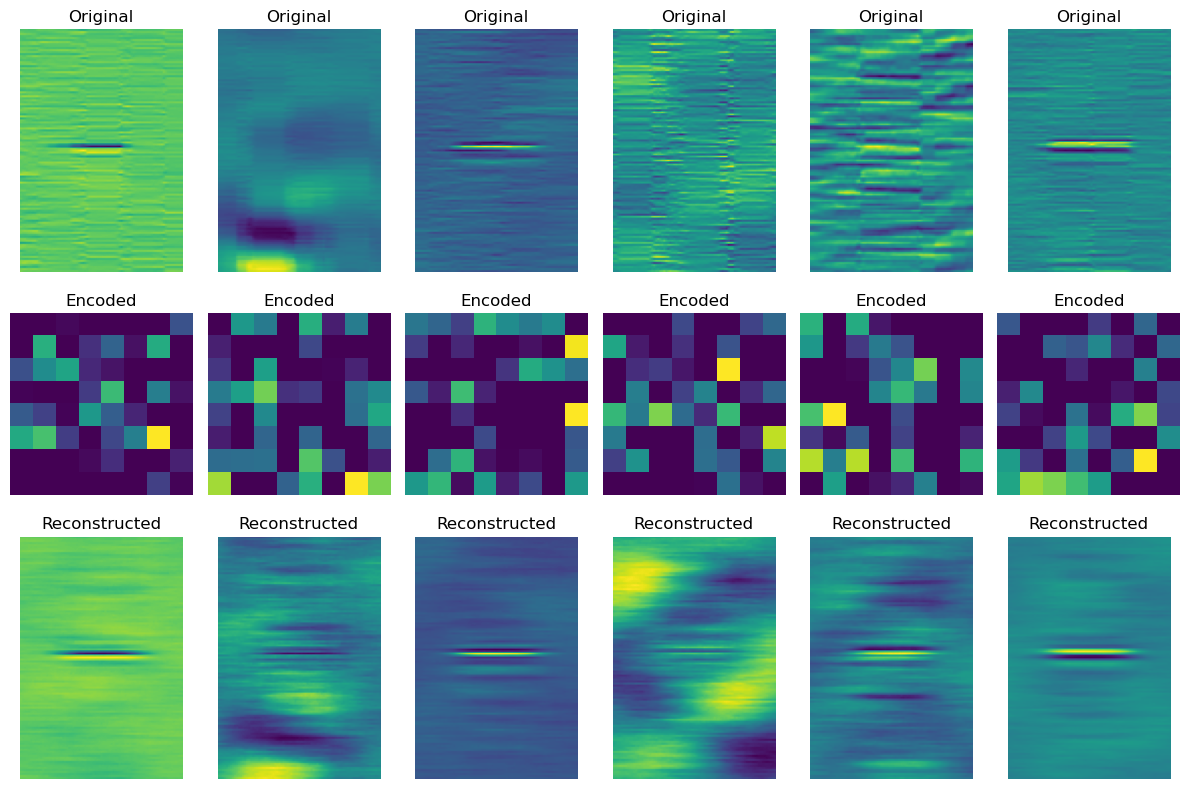

In [54]:
# encode the data
latent_dimensions = 64
autoencoder = SimpleAutoencoder(latent_dimensions)
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

autoencoder.fit(x_train, x_train,
                epochs=50,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test, x_test))

# visualise the original and decoded images
encoded_imgs = autoencoder.encoder(x_test).numpy()
decoded_imgs = autoencoder.decoder(encoded_imgs).numpy()

n = 6
plt.figure(figsize=(12, 8))
for i in range(n):
    # Original
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(121, 81), cmap='bwr')
    plt.title("Original")
    plt.axis('off')

    # Encoded
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(encoded_imgs[i].reshape(8, 8), cmap='bwr')
    plt.title("Encoded")
    plt.axis('off')

    # Reconstructed
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].reshape(121, 81), cmap='bwr')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()